<a href="https://colab.research.google.com/github/prince-pokharna/MachineLearningTutorials/blob/main/SVM(Linear).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("used_device_data.csv")
df = df.dropna()

print("Available columns:", df.columns.tolist())

# Map columns to correct names based on standard used_device_data.csv schema
# Typically, 'int_memory' is 'internal_memory' and 'main_camera_mp' is 'rear_camera_mp'
rename_dict = {
    'internal_memory': 'int_memory',
    'rear_camera_mp': 'main_camera_mp'
}
df = df.rename(columns={col: rename_dict[col] for col in rename_dict if col in df.columns})

median_price = df["normalized_used_price"].median()
df["expensive"] = (df["normalized_used_price" ] > median_price).astype(int)

features = ["ram", "battery", "int_memory", "screen_size", "main_camera_mp"]

# Ensure features exist in dataframe
features = [f for f in features if f in df.columns]
print("Using features:", features)

X = df[features]
y = df["expensive"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Available columns: ['device_brand', 'os', 'screen_size', '4g', '5g', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_used_price', 'normalized_new_price']
Using features: ['ram', 'battery', 'int_memory', 'screen_size', 'main_camera_mp']


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [10]:
model = SVC(kernel='linear', random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [11]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Cheap", "Expensive"]))

Accuracy: 0.8740

Classification Report:
              precision    recall  f1-score   support

       Cheap       0.91      0.83      0.87       325
   Expensive       0.84      0.92      0.88       326

    accuracy                           0.87       651
   macro avg       0.88      0.87      0.87       651
weighted avg       0.88      0.87      0.87       651



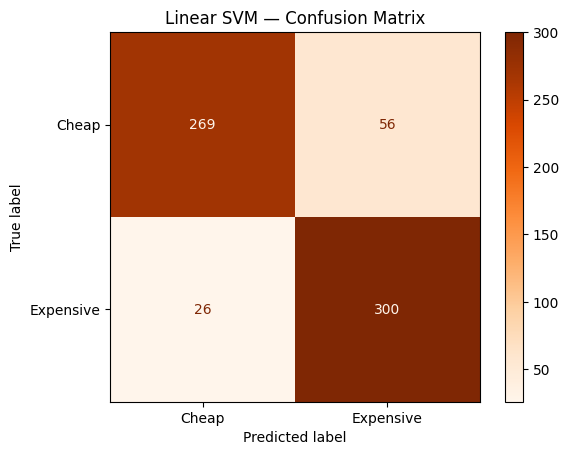

In [12]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cheap", "Expensive"])
disp.plot(cmap="Oranges")
plt.title("Linear SVM — Confusion Matrix")
plt.show()

In [13]:
print("Number of Support Vectors per class:", model.n_support_)
print("Total Support Vectors:", sum(model.n_support_))

Number of Support Vectors per class: [508 507]
Total Support Vectors: 1015
